In [2]:
%pip install duckdb pandas numpy scikit-learn lightgbm xgboost shap matplotlib seaborn plotly streamlit joblib

  Using cached pandas-3.1.1-cp312-cp312-win_amd64.whl.metadata (16 kB)
  Using cached numpy-2.5.5-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached streamlit-1.67.0-py3-none-any.whl.metadata (10 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached narwhals-2.29.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.3-py3-none-any.whl.metadata (7.1 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual profesional
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

# Rutas del proyecto
RAW_CSV_PATH = Path("../data/raw/cs-training.csv")
DB_PATH = Path("../data/processed/credit_risk.duckdb")
SQL_PATH = Path("../sql/01_analisis_exploratorio.sql")

assert RAW_CSV_PATH.exists(), f"No se encontró el archivo en {RAW_CSV_PATH.resolve()}"

# Conexión a DuckDB
con = duckdb.connect(str(DB_PATH))

# Verificamos las columnas exactas presentes en el CSV crudo
columnas_csv = con.execute(
    f"DESCRIBE SELECT * FROM read_csv_auto('{RAW_CSV_PATH.as_posix()}', nullstr='NA');"
).df()["column_name"].tolist()
print("Columnas detectadas en el CSV:", columnas_csv)

# Ingesta estructurada generando id_solicitante de forma robusta
con.execute(f"""
    CREATE OR REPLACE TABLE solicitudes_credito AS
    SELECT 
        ROW_NUMBER() OVER () AS id_solicitante,
        SeriousDlqin2yrs,
        RevolvingUtilizationOfUnsecuredLines,
        age,
        "NumberOfTime30-59DaysPastDueNotWorse",
        DebtRatio,
        MonthlyIncome,
        NumberOfOpenCreditLinesAndLoans,
        NumberOfTimes90DaysLate,
        NumberRealEstateLoansOrLines,
        "NumberOfTime60-89DaysPastDueNotWorse",
        NumberOfDependents
    FROM read_csv_auto('{RAW_CSV_PATH.as_posix()}', nullstr='NA');
""")

print("\nTabla 'solicitudes_credito' creada exitosamente en DuckDB.")
con.execute("DESCRIBE solicitudes_credito;").df()

Columnas detectadas en el CSV: ['column00', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Tabla 'solicitudes_credito' creada exitosamente en DuckDB.


,column_name,column_type,null,key,default,extra
0,id_solicitante,BIGINT,YES,None,None,None
1,SeriousDlqin2yrs,BIGINT,YES,None,None,None
2,RevolvingUtilizationOfUnsecuredLines,DOUBLE,YES,None,None,None
3,age,BIGINT,YES,None,None,None
4,NumberOfTime30-59DaysPastDueNotWorse,BIGINT,YES,None,None,None
5,DebtRatio,DOUBLE,YES,None,None,None
6,MonthlyIncome,BIGINT,YES,None,None,None
7,NumberOfOpenCreditLinesAndLoans,BIGINT,YES,None,None,None
8,NumberOfTimes90DaysLate,BIGINT,YES,None,None,None
9,NumberRealEstateLoansOrLines,BIGINT,YES,None,None,None


In [6]:
# Leemos y ejecutamos cada consulta separada por ';' en sql/01_analisis_exploratorio.sql
with open(SQL_PATH, "r", encoding="utf-8") as f:
    sql_script = f.read()

queries = [q.strip() for q in sql_script.split(";") if q.strip()]

for idx, query in enumerate(queries, start=1):
    print(f"\n{'='*70}\nRESULTADO CONSULTA SQL #{idx}\n{'='*70}")
    df_res = con.execute(query).df()
    display(df_res)

In [7]:
df = con.execute("SELECT * FROM solicitudes_credito").df()

# Tabla resumen de calidad y dispersión (percentiles clave para detectar outliers)
resumen_calidad = pd.DataFrame({
    "tipo_dato": df.dtypes,
    "nulos": df.isnull().sum(),
    "pct_nulos": (df.isnull().mean() * 100).round(2),
    "min": df.min(),
    "p50_mediana": df.median(),
    "p95": df.quantile(0.95),
    "p99": df.quantile(0.99),
    "max": df.max()
}).drop(index="id_solicitante")

display(resumen_calidad)

,tipo_dato,nulos,pct_nulos,min,p50_mediana,p95,p99,max
SeriousDlqin2yrs,int64,0,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000
RevolvingUtilizationOfUnsecuredLines,float64,0,0.0000,0.0000,0.1542,1.0000,1.0930,50708.0000
age,int64,0,0.0000,0.0000,52.0000,78.0000,87.0000,109.0000
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.0000,0.0000,0.0000,2.0000,4.0000,98.0000
DebtRatio,float64,0,0.0000,0.0000,0.3665,2449.0000,4979.0400,329664.0000
MonthlyIncome,Int64,29731,19.8200,0.0000,5400.0000,14587.6000,25000.0000,3008750.0000
NumberOfOpenCreditLinesAndLoans,int64,0,0.0000,0.0000,8.0000,18.0000,24.0000,58.0000
NumberOfTimes90DaysLate,int64,0,0.0000,0.0000,0.0000,1.0000,3.0000,98.0000
NumberRealEstateLoansOrLines,int64,0,0.0000,0.0000,1.0000,3.0000,4.0000,54.0000
NumberOfTime60-89DaysPastDueNotWorse,int64,0,0.0000,0.0000,0.0000,1.0000,2.0000,98.0000


,categoria_historial,cantidad_clientes,participacion_pct,defaults,tasa_default_pct
0,0_Codigo_Especial_96_98,269,0.1800,147.0000,54.6500
1,1_Sin_Atrasos_Previos,119637,79.7600,3264.0000,2.7300
2,2_Atraso_Leve_30_59_dias,17214,11.4800,2063.0000,11.9800
3,3_Atraso_Moderado_60_89_dias,4811,3.2100,1227.0000,25.5000
4,4_Atraso_Grave_90+_dias,8069,5.3800,3325.0000,41.2100


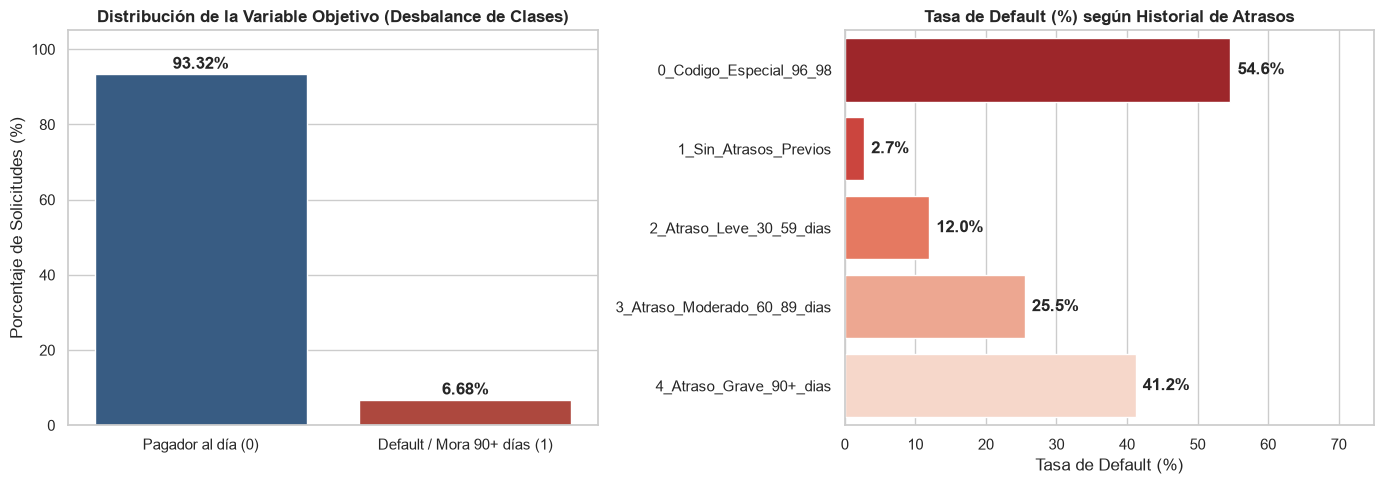

In [9]:
# Consulta de tasa de default según historial de morosidad
query_historial = """
WITH perfil_morosidad AS (
    SELECT 
        id_solicitante,
        SeriousDlqin2yrs,
        CASE 
            WHEN NumberOfTimes90DaysLate IN (96, 98) THEN '0_Codigo_Especial_96_98'
            WHEN NumberOfTimes90DaysLate > 0 THEN '4_Atraso_Grave_90+_dias'
            WHEN "NumberOfTime60-89DaysPastDueNotWorse" > 0 THEN '3_Atraso_Moderado_60_89_dias'
            WHEN "NumberOfTime30-59DaysPastDueNotWorse" > 0 THEN '2_Atraso_Leve_30_59_dias'
            ELSE '1_Sin_Atrasos_Previos'
        END AS categoria_historial
    FROM solicitudes_credito
)
SELECT 
    categoria_historial,
    COUNT(*) AS cantidad_clientes,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS participacion_pct,
    SUM(SeriousDlqin2yrs) AS defaults,
    ROUND(AVG(SeriousDlqin2yrs) * 100, 2) AS tasa_default_pct
FROM perfil_morosidad
GROUP BY categoria_historial
ORDER BY categoria_historial;
"""

df_hist = con.execute(query_historial).df()
display(df_hist)

# Visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

target_counts = df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100
sns.barplot(
    x=["Pagador al día (0)", "Default / Mora 90+ días (1)"],
    y=target_counts.values,
    hue=["Pagador al día (0)", "Default / Mora 90+ días (1)"],
    palette=["#2b5c8f", "#c0392b"],
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Distribución de la Variable Objetivo (Desbalance de Clases)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Porcentaje de Solicitudes (%)")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 1.5, f"{v:.2f}%", ha="center", fontweight="bold")
axes[0].set_ylim(0, 105)

sns.barplot(
    data=df_hist,
    x="tasa_default_pct",
    y="categoria_historial",
    hue="categoria_historial",
    palette="Reds_r",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Tasa de Default (%) según Historial de Atrasos", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tasa de Default (%)")
axes[1].set_ylabel("")
for i, v in enumerate(df_hist["tasa_default_pct"]):
    axes[1].text(v + 1, i, f"{v:.1f}%", va="center", fontweight="bold")
axes[1].set_xlim(0, 75)

plt.tight_layout()
plt.show()

con.close()